# Atividade 07 — Roteador de perguntas para o assistente RAG do TCC
**Henrique Ribeiro Leonardo** · Sistemas de Informação · UDF · 2026.2

Meu TCC (com Pedro Luiz Oliveira da Costa, orientação da Profa. Flávia Maria Alves Lopes) avalia uma arquitetura **RAG com modelos de linguagem de pequeno porte (SLMs)** rodando **localmente, sem GPU dedicada**, para consultar documentos sensíveis.

Em CPU, cada etapa custa tempo. A ideia testada aqui: um **classificador leve e supervisionado** que, antes da busca vetorial, prevê **a qual coleção de documentos** a pergunta pertence (ou se ela está fora do escopo). Assim a busca roda só numa parte da base, e perguntas fora do escopo nem chegam ao SLM.

Os dados são **sintéticos**, gerados por modelos de frase neste notebook. Nenhum documento ou pergunta real foi usado.

In [1]:
import sys, time, pickle, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
SEMENTE = 42
rng = np.random.default_rng(SEMENTE)
print('Python', sys.version.split()[0], '| scikit-learn', sklearn.__version__,
      '| pandas', pd.__version__, '| NumPy', np.__version__)

Python 3.13.18 | scikit-learn 1.9.1 | pandas 3.0.5 | NumPy 2.5.3


## 1. Dados sintéticos
Cinco classes: quatro coleções de documentos de uma empresa fictícia e uma classe **fora do escopo**. Para imitar o mundo real, a geração inclui perguntas sem acento, perguntas genéricas que servem para mais de uma coleção e 5% de rótulos trocados (erro de anotação).

In [2]:
modelos = {
 'rh': ['quantos dias de {a} eu tenho', 'como funciona o {a}', 'qual a regra de {a} para estagiário',
        'onde vejo meu {a}', 'posso pedir {a} no mês que vem', 'o que diz a política de {a}'],
 'juridico': ['qual o prazo do {a}', 'o {a} tem multa por rescisão', 'quem assinou o {a}',
              'qual cláusula fala de {a}', 'o {a} foi renovado', 'existe {a} com o fornecedor'],
 'financeiro': ['qual o valor da {a}', 'a {a} já foi paga', 'quando vence a {a}',
                'quem aprovou a {a}', 'qual centro de custo da {a}', 'tem {a} em atraso'],
 'ti_seguranca': ['como troco minha {a}', 'esqueci a {a}', 'quem libera {a}',
                  'qual a política de {a}', 'como configurar a {a}', 'a {a} está bloqueada'],
 'fora_escopo': ['{a}', 'me fala sobre {a}', 'você sabe {a}', 'o que acha de {a}'],
}
termos = {
 'rh': ['férias', 'vale-refeição', 'plano de saúde', 'banco de horas', 'holerite', 'home office',
        'licença', 'décimo terceiro', 'ponto eletrônico', 'auxílio creche'],
 'juridico': ['contrato de prestação', 'aditivo', 'termo de confidencialidade', 'contrato de locação',
              'acordo de nível de serviço', 'procuração', 'contrato com cliente', 'distrato'],
 'financeiro': ['nota fiscal', 'fatura do fornecedor', 'despesa de viagem', 'conta de energia',
                'parcela do empréstimo', 'reembolso', 'ordem de compra', 'duplicata'],
 'ti_seguranca': ['senha', 'VPN', 'conta de e-mail', 'autenticação em dois fatores', 'licença do antivírus',
                  'pasta compartilhada', 'chave de acesso', 'impressora da rede'],
 'fora_escopo': ['o jogo de ontem', 'a previsão do tempo', 'uma piada', 'receita de bolo',
                 'quem ganhou o oscar', 'um filme bom', 'a cotação do dólar', 'como está o trânsito'],
}
genericas = ['onde está o documento', 'preciso de ajuda com isso', 'qual o prazo', 'quem é o responsável',
             'tem alguma atualização', 'me manda o arquivo']
tira_acento = str.maketrans('áàâãéêíóôõúç', 'aaaaeeiooouc')

linhas = []
for classe, ms in modelos.items():
    for _ in range(160):
        txt = rng.choice(ms).format(a=rng.choice(termos[classe]))
        r = rng.random()
        if r < 0.20: txt = txt.translate(tira_acento)                  # digitado sem acento
        elif r < 0.27: txt = rng.choice(genericas)                      # pergunta ambígua
        if rng.random() < 0.30: txt = rng.choice(['oi, ', 'por favor, ', 'bom dia, ']) + txt
        rotulo = classe if rng.random() >= 0.05 else rng.choice(list(modelos))  # 5% rótulo errado
        linhas.append({'pergunta': txt, 'colecao': rotulo})
dados = pd.DataFrame(linhas).sample(frac=1, random_state=SEMENTE).reset_index(drop=True)
dados.to_csv('../dados/perguntas_rag_sinteticas.csv', index=False)
print(dados.shape); print(dados['colecao'].value_counts().to_string())
print(); print(dados.head(8).to_string(index=False))

(800, 2)
colecao
ti_seguranca    164
fora_escopo     163
financeiro      159
rh              158
juridico        156

                                                pergunta      colecao
                           você sabe quem ganhou o oscar  fora_escopo
                      me fala sobre como esta o transito  fora_escopo
      por favor, quantos dias de plano de saude eu tenho           rh
                  esqueci a autenticação em dois fatores ti_seguranca
bom dia, qual a regra de decimo terceiro para estagiario           rh
                                           esqueci a VPN ti_seguranca
               bom dia, quando vence a despesa de viagem   financeiro
       por favor, qual a política de pasta compartilhada ti_seguranca


## 2. Divisão e escolha do modelo (só no treino)
Holdout estratificado 75/25. Comparo, com validação cruzada estratificada em 5 partes:

- **referência**: sempre a classe mais frequente;
- **Naive Bayes** com TF-IDF de palavras (muito leve);
- **Regressão logística** com TF-IDF de n-gramas de caracteres (tolera falta de acento e erro de digitação).

Toda a vetorização fica **dentro do Pipeline**, aprendida só na parte de treino de cada dobra.

In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(dados['pergunta'], dados['colecao'], test_size=0.25,
                                          stratify=dados['colecao'], random_state=SEMENTE)
print('Treino:', len(X_tr), '| Teste:', len(X_te))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
candidatos = {
 'referencia': Pipeline([('v', TfidfVectorizer()), ('m', DummyClassifier(strategy='most_frequent'))]),
 'nb_palavras_a0.1': Pipeline([('v', TfidfVectorizer(ngram_range=(1, 2))), ('m', MultinomialNB(alpha=0.1))]),
 'nb_palavras_a1': Pipeline([('v', TfidfVectorizer(ngram_range=(1, 2))), ('m', MultinomialNB(alpha=1.0))]),
 'logreg_char_C1': Pipeline([('v', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4))),
                             ('m', LogisticRegression(C=1, max_iter=2000))]),
 'logreg_char_C10': Pipeline([('v', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4))),
                              ('m', LogisticRegression(C=10, max_iter=2000))]),
}
tab = []
for nome, p in candidatos.items():
    s = cross_validate(p, X_tr, y_tr, cv=cv, scoring=('accuracy', 'f1_macro'), return_train_score=True)
    tab.append({'modelo': nome, 'acc_treino': s['train_accuracy'].mean(),
                'acc_validacao': s['test_accuracy'].mean(), 'desvio': s['test_accuracy'].std(),
                'f1_macro_val': s['test_f1_macro'].mean()})
tab = pd.DataFrame(tab); print(tab.round(4).to_string(index=False))

Treino: 600 | Teste: 200
          modelo  acc_treino  acc_validacao  desvio  f1_macro_val
      referencia      0.2050         0.2033  0.0041        0.0676
nb_palavras_a0.1      0.9350         0.9183  0.0178        0.9189
  nb_palavras_a1      0.9333         0.9183  0.0178        0.9189
  logreg_char_C1      0.9329         0.9183  0.0178        0.9190
 logreg_char_C10      0.9400         0.9083  0.0175        0.9087


## 3. Custo em CPU
Como o TCC roda sem GPU, o custo do roteador importa tanto quanto a acurácia. Medi o tamanho do modelo serializado e o tempo médio para classificar uma pergunta (treino completo, mesma máquina).

In [4]:
custo = []
for nome in ['nb_palavras_a0.1', 'logreg_char_C10']:
    p = candidatos[nome].fit(X_tr, y_tr)
    tam = len(pickle.dumps(p)) / 1024
    amostra = list(X_tr[:200])
    t0 = time.perf_counter()
    for _ in range(5):
        for q in amostra: p.predict([q])
    ms = (time.perf_counter() - t0) / (5 * len(amostra)) * 1000
    custo.append({'modelo': nome, 'tamanho_KB': round(tam, 1), 'ms_por_pergunta': round(ms, 3)})
custo = pd.DataFrame(custo); print(custo.to_string(index=False))

          modelo  tamanho_KB  ms_por_pergunta
nb_palavras_a0.1        63.9            0.460
 logreg_char_C10        89.8            0.468


In [5]:
# Regra decidida antes do teste: maior F1 macro de validação; empate técnico (< 0,01) -> modelo mais leve.
validos = tab[tab['modelo'] != 'referencia'].sort_values('f1_macro_val', ascending=False)
top = validos.iloc[0]
empate = validos[validos['f1_macro_val'] >= top['f1_macro_val'] - 0.01]['modelo'].tolist()
ESCOLHIDO = next((m for m in empate if m.startswith('nb')), top['modelo'])
print('Empate técnico:', empate, '-> escolhido:', ESCOLHIDO)

Empate técnico: ['logreg_char_C1', 'nb_palavras_a0.1', 'nb_palavras_a1'] -> escolhido: nb_palavras_a0.1


## 4. Teste final (uma única vez)

Modelo nb_palavras_a0.1: acurácia 0.9000 | F1 macro 0.8985 | referência 0.2050

              precision    recall  f1-score   support

  financeiro      0.868     0.825     0.846        40
 fora_escopo      0.870     0.976     0.920        41
    juridico      0.861     0.795     0.827        39
          rh      0.927     0.974     0.950        39
ti_seguranca      0.974     0.927     0.950        41

    accuracy                          0.900       200
   macro avg      0.900     0.899     0.898       200
weighted avg      0.900     0.900     0.899       200



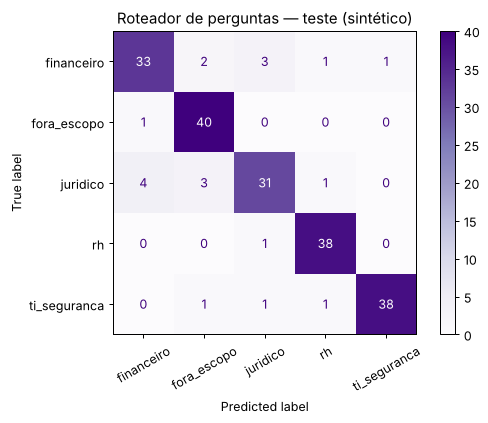

In [6]:
final = candidatos[ESCOLHIDO].fit(X_tr, y_tr)
ref = candidatos['referencia'].fit(X_tr, y_tr)
prev = final.predict(X_te)
acc, f1m = accuracy_score(y_te, prev), f1_score(y_te, prev, average='macro')
acc_ref = accuracy_score(y_te, ref.predict(X_te))
print(f'Modelo {ESCOLHIDO}: acurácia {acc:.4f} | F1 macro {f1m:.4f} | referência {acc_ref:.4f}\n')
print(classification_report(y_te, prev, digits=3))
classes = sorted(dados['colecao'].unique())
cm = confusion_matrix(y_te, prev, labels=classes)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap='Purples', xticks_rotation=30)
plt.title('Roteador de perguntas — teste (sintético)'); plt.tight_layout()
plt.savefig('../assets/henrique-tcc-matriz.png', dpi=110); plt.show()

## 5. Rotear só quando houver confiança
Se a confiança do roteador for baixa, o sistema **não filtra**: faz a busca em todas as coleções, como faria sem o classificador. O erro do roteador, então, só custa tempo, não resposta.

In [7]:
proba = final.predict_proba(X_te)
conf = proba.max(axis=1)
pred = final.classes_[proba.argmax(axis=1)]
lim_tab = []
for lim in [0.0, 0.4, 0.5, 0.6, 0.7]:
    m = conf >= lim
    lim_tab.append({'limiar': lim, 'roteadas_%': m.mean()*100,
                    'acuracia_nas_roteadas': accuracy_score(y_te[m], pred[m]) if m.any() else np.nan})
lim_tab = pd.DataFrame(lim_tab); print(lim_tab.round(3).to_string(index=False))

exemplos = ['quantos dias de ferias eu tenho', 'esqueci minha senha da vpn', 'a nota fiscal do fornecedor foi paga',
            'qual o prazo', 'quem ganhou o jogo ontem', 'o contrato tem multa se eu sair antes']
pe = final.predict_proba(exemplos)
print()
for q, p in zip(exemplos, pe):
    print(f'{q!r:45} -> {final.classes_[p.argmax()]:13} (confiança {p.max():.2f})')

 limiar  roteadas_%  acuracia_nas_roteadas
    0.0       100.0                  0.900
    0.4       100.0                  0.900
    0.5        96.5                  0.922
    0.6        93.5                  0.947
    0.7        93.5                  0.947

'quantos dias de ferias eu tenho'             -> rh            (confiança 1.00)
'esqueci minha senha da vpn'                  -> ti_seguranca  (confiança 1.00)
'a nota fiscal do fornecedor foi paga'        -> financeiro    (confiança 1.00)
'qual o prazo'                                -> juridico      (confiança 0.81)
'quem ganhou o jogo ontem'                    -> fora_escopo   (confiança 1.00)
'o contrato tem multa se eu sair antes'       -> juridico      (confiança 0.96)


In [8]:
json.dump({'escolhido': ESCOLHIDO, 'validacao': tab.to_dict(orient='records'),
           'custo': custo.to_dict(orient='records'), 'teste': {'acuracia': acc, 'f1_macro': f1m,
           'referencia': acc_ref}, 'limiares': lim_tab.to_dict(orient='records')},
          open('resultados_tcc_henrique.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=2, default=float)
print('Salvo em notebooks/resultados_tcc_henrique.json')

Salvo em notebooks/resultados_tcc_henrique.json


## Limites
Vocabulário e classes foram escritos por mim, então a separação entre coleções é mais limpa do que numa empresa real. O tempo medido é de uma máquina de nuvem, não do hardware do TCC; precisa ser medido de novo no computador de testes. Com documentos reais, o treino exigiria perguntas reais rotuladas, com autorização e sem conteúdo sensível nos rótulos.